# Extending truncFLR and fdaSP to dependent data

Previously, we generated $X_i$ as i.i.d. curves. Here we relax that: $X_t$ is instead generated by a functional autoregressive process of order 1, i.e. an FAR(1) process,

$$X_t(s) = \int_0^1 \psi(s, r) X_{t-1}(r) \, dr + \varepsilon_t(s), \qquad t = 1, \dots, n,$$

a standard model for functional time series (Bosq [[13]](../docs/references.md#ref-bosq-2000)). $\varepsilon_t$ are i.i.d.
Gaussian-process innovations.

This notebook checks how well the methods work with this kind of data, and how much the answer
depends on which operator $\psi$ we choose.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from fts_research.far import far_dgp

plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

The kernel from chapter 3 of Bosq [[13]](../docs/references.md#ref-bosq-2000) is
$$\psi(s, r) = \exp\{-(s^2 + r^2)/2\},$$
rescaled to a target Hilbert-Schmidt norm $\rho$. A $\rho < 1$ is sufficient (Bosq [[13]](../docs/references.md#ref-bosq-2000), Thm 3.1) for the process to admit a strictly stationary, causal solution, and we use $\rho = 0.7$ throughout.

It is worth noticing what this kernel is before using it as a stress test. It factorises as $\exp(-s^2/2)\exp(-r^2/2)$, so the operator has **rank one**: only the component of $X_{t-1}$ along $\exp(-r^2/2)$ carries forward, and every direction orthogonal to that one is i.i.d. across $t$. Almost all of the covariance structure is therefore untouched by the dependence.

So we also use a second kernel with no such factorisation,
$$\psi(s, r) = \exp(-|s - r| / \texttt{scale}),$$
which has full rank and eigenvalues decaying like $j^{-2}$, so every direction in $L^2$ is autocorrelated.

In [2]:
grid = np.linspace(0, 1, 500)
rho = 0.7
kernels = {"Bosq (rank one)": far_dgp.gaussian_kernel,
           "exponential (full rank)": far_dgp.exponential_kernel}

print(f"{'kernel':26}{'HS norm':>10}{'operator norm':>15}{'rank':>7}")
for name, fn in kernels.items():
    K = fn(grid, rho=rho)
    print(f"{name:26}{far_dgp.hs_norm(K, grid):10.4f}"
          f"{far_dgp.operator_norm(K, grid):15.4f}{far_dgp.kernel_rank(K, grid):7d}")

kernel                       HS norm  operator norm   rank
Bosq (rank one)               0.7000         0.7000      1
exponential (full rank)       0.7000         0.5801    500


Both are contractive, so both are stationary. The rank-one kernel has its two norms equal, which is exactly the signature of rank one; the full-rank kernel spreads the same Hilbert-Schmidt budget over every direction, so its operator norm is strictly smaller. Matching two operators on $\|\Psi\|_{HS}$ therefore does not match them on how persistent their strongest direction is, and we should not expect the two to be equally hard.

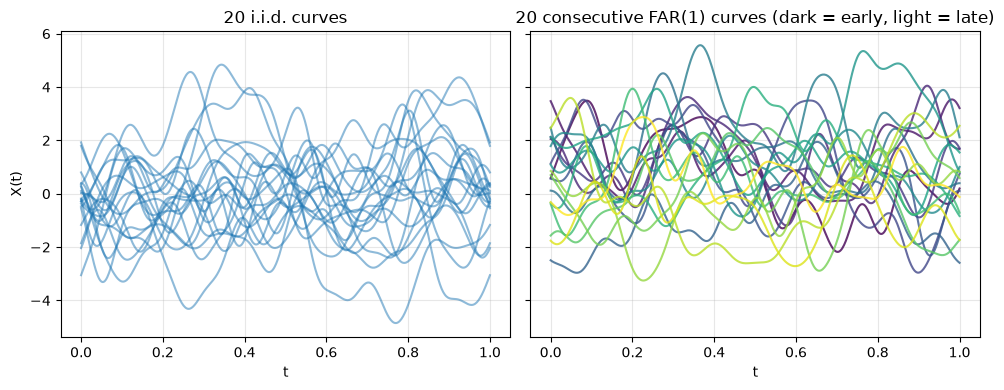

In [3]:
from fts_research.core.gp import sample_gp

Psi = far_dgp.gaussian_kernel(grid, rho=rho)
X_iid = sample_gp(20, grid, rng=0)
X_far = far_dgp.sample_far1(20, grid, Psi, burn_in=200, rng=0)

fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
ax[0].plot(grid, X_iid.T, alpha=0.5, color="C0")
ax[0].set_title("20 i.i.d. curves")
ax[0].set_xlabel("t"); ax[0].set_ylabel("X(t)")

cmap = plt.cm.viridis
for i, x in enumerate(X_far):
    ax[1].plot(grid, x, color=cmap(i / (len(X_far) - 1)), alpha=0.8)
ax[1].set_title("20 consecutive FAR(1) curves (dark = early, light = late)")
ax[1].set_xlabel("t")
plt.tight_layout(); plt.show()

To see the difference the rank makes, we project the curves onto two directions: $\exp(-r^2/2)$, which is the one the Bosq kernel acts on, and $\sin(2\pi t)$ orthogonalised against it. Under a rank-one operator the second should show no serial dependence at all.

In [4]:
g0 = np.exp(-grid ** 2 / 2)
probe = np.sin(2 * np.pi * grid)
probe = probe - np.trapezoid(probe * g0, grid) / np.trapezoid(g0 ** 2, grid) * g0
directions = {r"along $\exp(-r^2/2)$": g0, r"orthogonal to it": probe}

print(f"{'kernel':26}{'along exp(-r^2/2)':>20}{'orthogonal':>14}")
series = {}
for name, fn in kernels.items():
    X_long = far_dgp.sample_far1(2000, grid, fn(grid, rho=rho), burn_in=200, rng=1)
    row = []
    for dname, d in directions.items():
        s = np.trapezoid(X_long * d, grid, axis=1)
        series[(name, dname)] = s
        row.append(far_dgp.lag1_autocorr(s))
    print(f"{name:26}{row[0]:20.4f}{row[1]:14.4f}")

X_iid_long = sample_gp(2000, grid, rng=1)
row = [far_dgp.lag1_autocorr(np.trapezoid(X_iid_long * d, grid, axis=1))
       for d in directions.values()]
print(f"{'i.i.d. curves':26}{row[0]:20.4f}{row[1]:14.4f}")

kernel                       along exp(-r^2/2)    orthogonal
Bosq (rank one)                         0.6950       -0.0135
exponential (full rank)                 0.5657        0.2899
i.i.d. curves                           0.0172       -0.0008


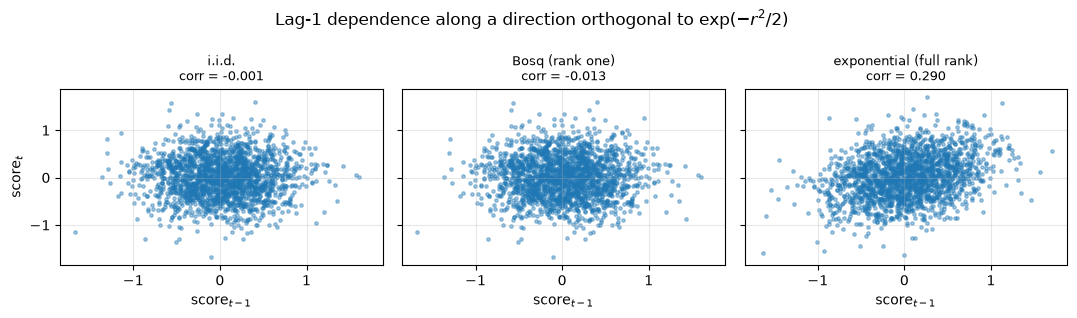

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2), sharey=True, sharex=True)
panels = [("i.i.d.", np.trapezoid(X_iid_long * probe, grid, axis=1)),
          ("Bosq (rank one)", series[("Bosq (rank one)", r"orthogonal to it")]),
          ("exponential (full rank)", series[("exponential (full rank)", r"orthogonal to it")])]
for a, (name, s) in zip(ax, panels):
    a.scatter(s[:-1], s[1:], s=6, alpha=0.4)
    a.set_title(f"{name}\ncorr = {far_dgp.lag1_autocorr(s):.3f}", fontsize=9)
    a.set_xlabel(r"score$_{t-1}$")
ax[0].set_ylabel(r"score$_t$")
plt.suptitle(r"Lag-1 dependence along a direction orthogonal to $\exp(-r^2/2)$")
plt.tight_layout(); plt.show()

We can see that the Bosq kernel leaves that direction essentially i.i.d., while the exponential kernel does not. So the rank-one kernel perturbs a one-dimensional subspace and leaves the rest of the covariance structure alone, which is a much narrower departure from independence than it looks. We run both from here on rather than generalising from either.

## Truncated endpoint estimation (Hall & Hooker) under FAR(1)

We regenerate the same windowed model as in `truncFLR.ipynb` ($u=0.8$, $v=1.0$, $\text{snr}=26.25$), but $X$ now comes from an FAR(1) process instead of i.i.d. curves. `HH.fit_mirror` is applied completely unmodified, and nothing about the true endpoint is passed to it.

Bosq (rank one)            lambda = 0.09639, u_hat = 0.8100 (true u = 0.8)


exponential (full rank)    lambda = 0.1004, u_hat = 0.8100 (true u = 0.8)


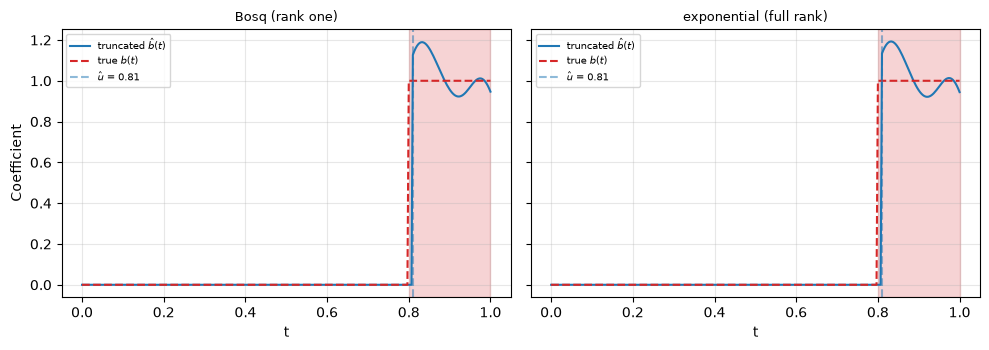

In [6]:
from fts_research.truncFLR import HH

u, v = 0.8, 1.0
grid_hh = np.linspace(0, 1, 301)
lambdas = np.linspace(0.0, 1.0, 250)[1:]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a, (name, fn) in zip(ax, kernels.items()):
    d = far_dgp.sim_dataset_window(n=200, grid=grid_hh, u=u, v=v, snr=26.25, rho=rho,
                                   kernel=fn, rng=123)
    res = HH.fit_mirror(d["X"], d["Y"], d["grid"], lambdas=lambdas)
    print(f"{name:26} lambda = {res['lam_hat']:.4g}, u_hat = {res['u_hat']:.4f} "
          f"(true u = {u})")

    a.plot(grid_hh, res["b_hat"], color="C0", lw=1.5, label=r"truncated $\hat{b}(t)$")
    a.plot(grid_hh, d["b"], color="C3", lw=1.5, ls="--", label=r"true $b(t)$")
    a.axvline(res["u_hat"], color="C0", alpha=0.5, ls="--",
              label=fr"$\hat u$ = {res['u_hat']:.2f}")
    a.axvspan(u, v, color="C3", alpha=0.2)
    a.set_xlabel("t"); a.set_title(name, fontsize=9); a.legend(fontsize=7)
ax[0].set_ylabel("Coefficient")
plt.tight_layout(); plt.show()

One draw is not evidence, so we repeat over independent replications and compare against the i.i.d. case from `truncFLR.ipynb`.

In [7]:
from fts_research.truncFLR import HH_dgp

n_rep = 40
designs = {"i.i.d.": None} | kernels
hh_err = {}
for name, fn in designs.items():
    errs = np.empty(n_rep)
    for r in range(n_rep):
        if fn is None:
            d = HH_dgp.sim_dataset(n=200, n_grid=301, u=u, v=v, snr=26.25, rng=r)
        else:
            d = far_dgp.sim_dataset_window(n=200, grid=grid_hh, u=u, v=v, snr=26.25,
                                           rho=rho, kernel=fn, rng=r)
        errs[r] = HH.fit_mirror(d["X"], d["Y"], d["grid"], lambdas)["u_hat"] - u
    hh_err[name] = errs
    print(f"{name}: done")

print(f"\n{n_rep} replications\n")
print(f"{'design':26}{'bias':>9}{'sd':>9}{'RMSE':>9}")
for name, e in hh_err.items():
    print(f"{name:26}{e.mean():+9.4f}{e.std(ddof=1):9.4f}{np.sqrt((e ** 2).mean()):9.4f}")

i.i.d.: done


Bosq (rank one): done


exponential (full rank): done

40 replications

design                         bias       sd     RMSE
i.i.d.                      -0.0022   0.0130   0.0131
Bosq (rank one)             -0.0018   0.0130   0.0130
exponential (full rank)     -0.0007   0.0110   0.0109


## Locally sparse estimation (OGL) under FAR(1)

We regenerate the piecewise-sine model $\psi_1$ (zero on $[0.3, 0.7]$) from `LocSpaFLR_f2s.ipynb`. The rows here are consecutive curves from a stationary process rather than overlapping windows of one series, so they are dependent but not near-duplicates; we still block the folds, since random folds would scatter neighbouring times across the split.

Bosq (rank one)            ISE = 0.1327


exponential (full rank)    ISE = 0.1400


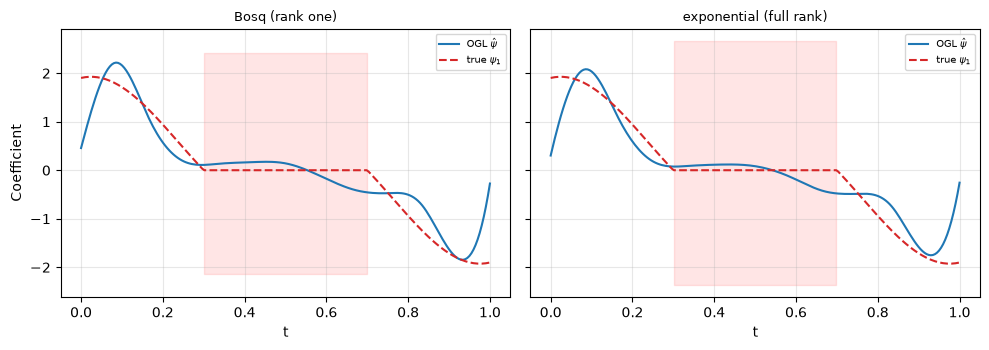

In [8]:
from fts_research.fdaSP import SBC, SBC_sim

grid_sp = np.linspace(0, 1, 200)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for a, (name, fn) in zip(ax, kernels.items()):
    X_sp, y_sp, _, beta_true_sp = far_dgp.sim_dataset_psi(
        n=50, grid=grid_sp, psi_fn=far_dgp.psi1, rho=rho, kernel=fn, rng=123
    )
    cv = SBC.cv_fit(X_sp, y_sp, grid_sp, n_basis=15, n_folds=5,
                    folds=SBC.blocked_folds(len(y_sp), 5), rng=123)
    print(f"{name:26} ISE = {SBC_sim.ise(cv['beta'], beta_true_sp, grid_sp):.4f}")

    a.plot(grid_sp, cv["beta"], color="C0", lw=1.5, label=r"OGL $\hat\psi$")
    a.plot(grid_sp, beta_true_sp, color="C3", lw=1.5, ls="--", label=r"true $\psi_1$")
    nm = (grid_sp >= 0.3) & (grid_sp <= 0.7)
    a.fill_between(grid_sp, *a.get_ylim(), where=nm, alpha=0.1, color="red")
    a.set_xlabel("t"); a.set_title(name, fontsize=9); a.legend(fontsize=7)
ax[0].set_ylabel("Coefficient")
plt.tight_layout(); plt.show()

We repeat over independent FAR(1) datasets for each of the three test functions and each kernel, and compare ISE between the OGL and its competitors.

In [9]:
import warnings
warnings.filterwarnings("ignore")

psi_fns = {"psi1": far_dgp.psi1, "psi2": far_dgp.psi2, "psi3": far_dgp.psi3}
null_fns = {
    "psi1": lambda g: (g >= 0.3) & (g <= 0.7),
    "psi2": lambda g: (g < 0.25) | (g > 0.75),
    "psi3": lambda g: np.zeros_like(g, dtype=bool),
}
methods = ["Ogl", "Lasso", "Ridge", "Enet", "Splines", "FPCA"]

n_rep = 30
results_far = {}
for kname, kfn in kernels.items():
    for name, psi_fn in psi_fns.items():
        acc = {m: {"ise": [], "ise_T0": [], "ise_T1": []} for m in methods}
        for r in range(n_rep):
            X_r, y_r, _, beta_true_r = far_dgp.sim_dataset_psi(
                n=50, grid=grid_sp, psi_fn=psi_fn, rho=rho, kernel=kfn, rng=2000 + r
            )
            T0 = null_fns[name](grid_sp)
            cv_r = SBC.cv_fit(X_r, y_r, grid_sp, n_basis=15, n_folds=5,
                              folds=SBC.blocked_folds(len(y_r), 5), rng=r)
            betas = {"Ogl": cv_r["beta"]}
            betas.update(SBC_sim.fit_comps(X_r, y_r, grid_sp, cv_r["W"], cv_r["Phi"]))

            for mname, bh in betas.items():
                acc[mname]["ise"].append(SBC_sim.ise(bh, beta_true_r, grid_sp))
                acc[mname]["ise_T0"].append(SBC_sim.ise(bh, beta_true_r, grid_sp, T0))
                acc[mname]["ise_T1"].append(SBC_sim.ise(bh, beta_true_r, grid_sp, ~T0))
        results_far[(kname, name)] = {
            m: {k: np.asarray(v) for k, v in dd.items()} for m, dd in acc.items()
        }
    print(f"{kname}: done ({n_rep} reps x 3 functions)")

Bosq (rank one): done (30 reps x 3 functions)


exponential (full rank): done (30 reps x 3 functions)


In [10]:
print(f"{'kernel':16}{'fn':6}{'method':9}{'ISE mean':>10}{'ISE sd':>9}"
      f"{'ISE_T0':>9}{'ISE_T1':>9}")
for (kname, fname), per_method in results_far.items():
    short = "rank one" if "rank one" in kname else "full rank"
    for m in methods:
        d = per_method[m]
        print(f"{short:16}{fname:6}{m:9}{d['ise'].mean():10.4f}"
              f"{d['ise'].std(ddof=1):9.4f}{np.nanmean(d['ise_T0']):9.4f}"
              f"{np.nanmean(d['ise_T1']):9.4f}")

kernel          fn    method     ISE mean   ISE sd   ISE_T0   ISE_T1
rank one        psi1  Ogl          0.1466   0.0761   0.0133   0.1334
rank one        psi1  Lasso        0.2686   0.0858   0.0168   0.2518
rank one        psi1  Ridge        0.2035   0.1373   0.0267   0.1768
rank one        psi1  Enet         0.2167   0.0909   0.0199   0.1968
rank one        psi1  Splines      2.3115   3.3658   0.1235   2.1880
rank one        psi1  FPCA         0.2985   0.0654   0.0536   0.2449
rank one        psi2  Ogl          0.0230   0.0188   0.0071   0.0159
rank one        psi2  Lasso        0.0425   0.0266   0.0075   0.0350
rank one        psi2  Ridge        0.0417   0.0619   0.0209   0.0208
rank one        psi2  Enet         0.0290   0.0204   0.0074   0.0216
rank one        psi2  Splines      1.9526   2.8501   1.8342   0.1184
rank one        psi2  FPCA         0.0611   0.0547   0.0267   0.0345
rank one        psi3  Ogl          0.0411   0.0206      nan   0.0411
rank one        psi3  Lasso       

For a like-for-like comparison against the i.i.d. case, we rerun the same study on independent curves at the same sample size.

In [11]:
iid_res = SBC_sim.run_sim(n_rep=n_rep, n=50, m=len(grid_sp), n_folds=5, verbose=False)

print(f"OGL mean ISE, {n_rep} replications\n")
print(f"{'design':16}{'op norm':>9}{'psi1':>9}{'psi2':>9}{'psi3':>9}")
print(f"{'i.i.d.':16}{'0':>9}" + "".join(f"{iid_res[f]['Ogl']['ise'].mean():9.4f}"
                                         for f in ["psi1", "psi2", "psi3"]))
for kname, kfn in kernels.items():
    short = "rank one" if "rank one" in kname else "full rank"
    opn = far_dgp.operator_norm(kfn(grid_sp, rho=rho), grid_sp)
    print(f"{short:16}{opn:9.3f}"
          + "".join(f"{results_far[(kname, f)]['Ogl']['ise'].mean():9.4f}"
                    for f in ["psi1", "psi2", "psi3"]))

OGL mean ISE, 30 replications

design            op norm     psi1     psi2     psi3
i.i.d.                  0   0.0964   0.0163   0.0186
rank one            0.700   0.1466   0.0230   0.0411
full rank           0.580   0.2814   0.0217   0.0427


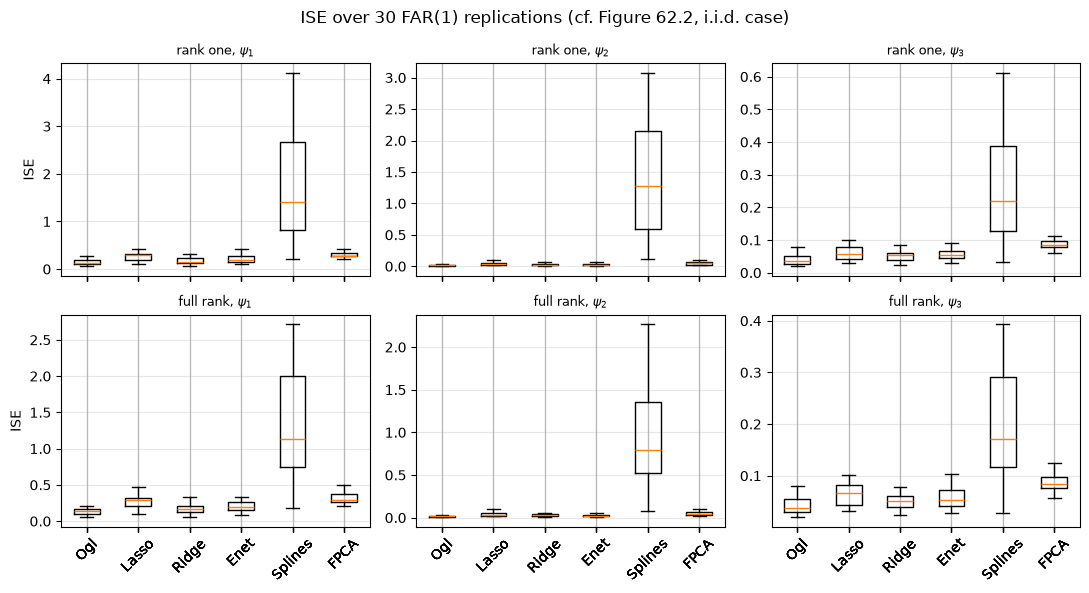

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharex=True)
for row, kname in enumerate(kernels):
    short = "rank one" if "rank one" in kname else "full rank"
    for ax, fname in zip(axes[row], ["psi1", "psi2", "psi3"]):
        ax.boxplot([results_far[(kname, fname)][m]["ise"] for m in methods],
                   tick_labels=methods, showfliers=False)
        ax.tick_params(axis="x", rotation=45)
        ax.set_title(fr"{short}, $\{fname[:3]}_{fname[-1]}$", fontsize=9)
    axes[row][0].set_ylabel("ISE")
plt.suptitle(f"ISE over {n_rep} FAR(1) replications (cf. Figure 62.2, i.i.d. case)")
plt.tight_layout(); plt.show()

## Summary

Neither estimator breaks under serial dependence, and both continue to recover the right part of the domain. What changes is precision: dependence reduces the effective sample size, so the same $n$ carries less information about the covariance operator, and the OGL's ISE rises against the i.i.d. baseline on all three functions and both kernels. Among the competitors the unpenalised spline fit on $W$ is the worst affected by a wide margin, having no regularisation to absorb the loss.

Which kernel is harder is a subtler question than the rank alone answers. The Bosq kernel touches one direction in $L^2$ and leaves every other i.i.d.; the exponential kernel touches all of them. But the two were matched on Hilbert-Schmidt norm, and spreading that budget across the spectrum lowers the operator norm from $0.70$ to $0.58$, so the full-rank kernel's most persistent direction is the weaker of the two. The ISEs come out mixed rather than ordered, and neither kernel dominates. The one gap that looks decisive, $\psi_1$ under the full-rank kernel, has a standard deviation of 0.7768 across replications against a mean of 0.2814, so it is a handful of extreme draws rather than a shift in the typical one.

The practical reading is that a single norm is not a sufficient summary of how much an operator will cost you: what matters is how the dependence is distributed across the spectrum, and two operators agreeing on $\|\Psi\|_{HS}$ can differ in both directions. Reporting a robustness check on one kernel says little about the next one.

Neither estimator has any theory behind it for dependent curves, so this is an empirical check rather than a guarantee. What it suggests is that the truncation and sparsity machinery survives dependence, and that the honest thing to widen for it is the uncertainty attached to $\hat u$ and $\hat\psi$, not the point estimates themselves.